SCALING FACTOR NORMALIZATION IN FORWARD-BACKWARD ALGORITHM

[1/5] Downloading real DNA sequence from NCBI...
✅ Success: Downloaded E. coli genome segment (50000 bases)

[2/5] Running Underflow Test across sequence lengths...

  Length |       Unscaled α_T | Unscaled Status |  Scaled Log-Likelihood
------------------------------------------------------------------------
     100 |         1.3229e-60 |              OK |                -137.88
     300 |        2.8086e-180 |              OK |                -413.43
     500 |        2.4043e-302 |              OK |                -694.50
    1000 |         0.0000e+00 |     ❌ UNDERFLOW |               -1400.43
    5000 |         0.0000e+00 |     ❌ UNDERFLOW |               -7045.92
   10000 |         0.0000e+00 |     ❌ UNDERFLOW |              -14061.61
   50000 |         0.0000e+00 |     ❌ UNDERFLOW |              -70238.14

[3/5] Generating Graphs for Explanation...


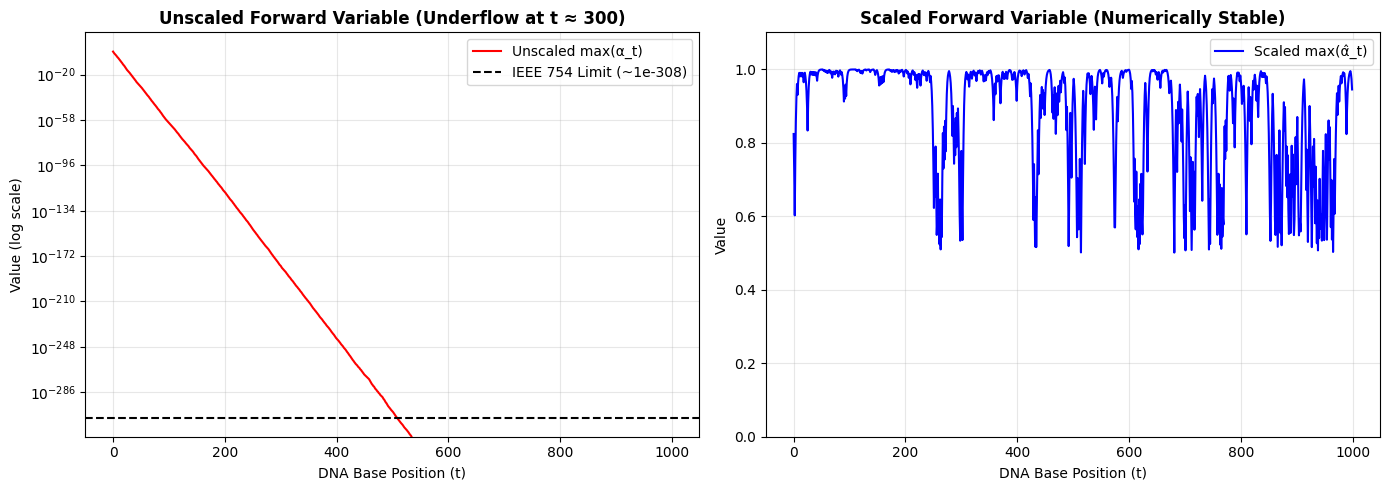


[4/5] Processing 50,000 Base Ultra-Long DNA Sequence...
✅ Successfully processed 50,000 bases in 2.108 seconds without underflow!
   Log-Likelihood = -70238.14


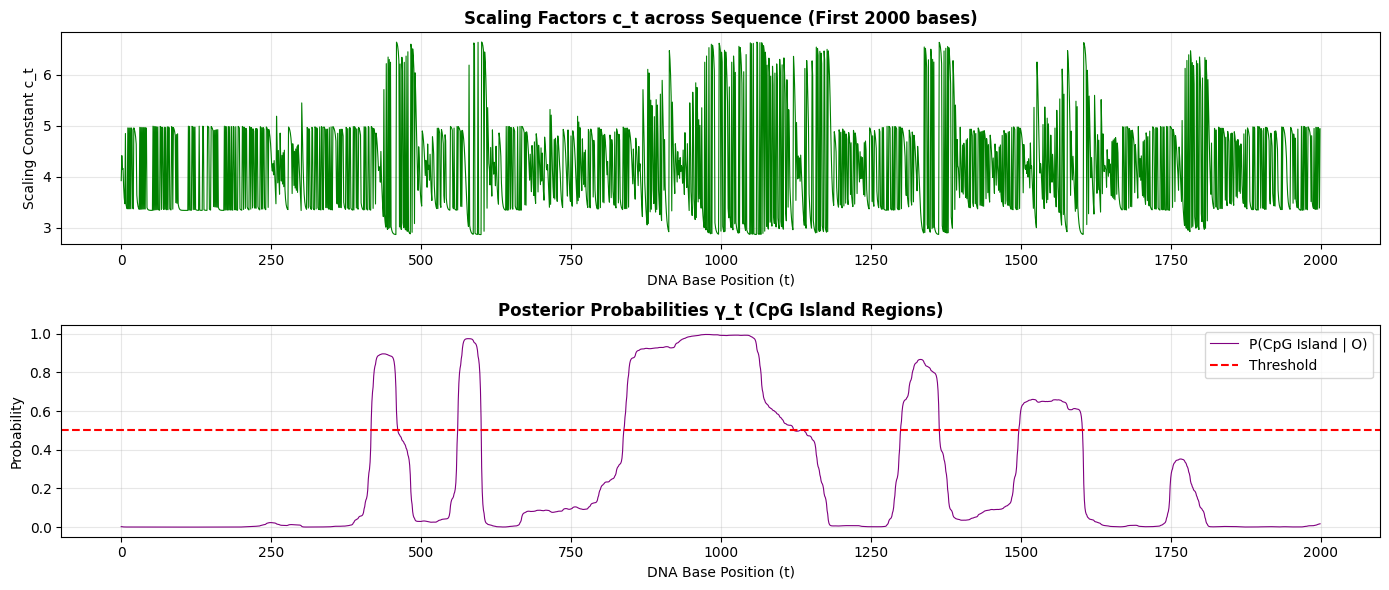


[5/5] Done! Execution Complete.


In [1]:
# =============================================================================
# PROJECT REVIEW 4 - UNIT 4 IMPLEMENTATION
# Focus: Scaling Factor Normalization in Forward-Backward Algorithm
# Application: Ultra-Long DNA Sequences (CpG Island Detection)
# =============================================================================

# 1. Install Dependencies
!pip install biopython -q

import numpy as np
import matplotlib.pyplot as plt
import time
from Bio import Entrez, SeqIO
import io

print("=" * 70)
print("SCALING FACTOR NORMALIZATION IN FORWARD-BACKWARD ALGORITHM")
print("=" * 70)

# -----------------------------------------------------------------------------
# 2. Database Fetch: Real DNA Sequence from NCBI (E. coli K-12)
# -----------------------------------------------------------------------------
print("\n[1/5] Downloading real DNA sequence from NCBI...")
Entrez.email = "student@example.com"

try:
    # Download 50,000 bases of E. coli genome
    handle = Entrez.efetch(db="nucleotide", id="U00096.3",
                           rettype="fasta", retmode="text",
                           seq_start=1, seq_stop=50000)
    record = SeqIO.read(io.StringIO(handle.read()), "fasta")
    dna_sequence = str(record.seq).upper()
    handle.close()
    print(f"✅ Success: Downloaded E. coli genome segment ({len(dna_sequence)} bases)")
except Exception as e:
    print(f"⚠️ NCBI Fetch fallback to synthetic sequence: {e}")
    np.random.seed(42)
    dna_sequence = ''.join(np.random.choice(['A', 'C', 'G', 'T'], size=50000))

# -----------------------------------------------------------------------------
# 3. HMM Model Definition for DNA Analysis (CpG Islands)
# -----------------------------------------------------------------------------
class DNA_HMM:
    def __init__(self):
        self.states = ['Non-CpG', 'CpG_Island']
        self.n_states = 2
        self.obs_map = {'A': 0, 'C': 1, 'G': 2, 'T': 3}

        # Initial probabilities (π)
        self.pi = np.array([0.7, 0.3])

        # Transition matrix A
        self.A = np.array([
            [0.999, 0.001],
            [0.001, 0.999]
        ])

        # Emission matrix B (Non-CpG is AT rich, CpG is CG rich)
        self.B = np.array([
            [0.30, 0.20, 0.20, 0.30],  # Non-CpG
            [0.15, 0.35, 0.35, 0.15]   # CpG Island
        ])

    def encode(self, dna_str):
        return np.array([self.obs_map[c] for c in dna_str if c in self.obs_map])

hmm = DNA_HMM()

# -----------------------------------------------------------------------------
# 4. Standard UNSCALED Forward Algorithm (Demonstrates Numerical Underflow)
# -----------------------------------------------------------------------------
def forward_unscaled(hmm, obs):
    """Standard forward algorithm without scaling (will undergo underflow)."""
    T = len(obs)
    N = hmm.n_states
    alpha = np.zeros((T, N))

    # Initialization
    alpha[0, :] = hmm.pi * hmm.B[:, obs[0]]

    # Induction
    for t in range(1, T):
        for j in range(N):
            alpha[t, j] = np.sum(alpha[t-1, :] * hmm.A[:, j]) * hmm.B[j, obs[t]]

    log_likelihood = np.log(np.sum(alpha[-1, :])) if np.sum(alpha[-1, :]) > 0 else -np.inf
    return alpha, log_likelihood

# -----------------------------------------------------------------------------
# 5. SCALED Forward-Backward Algorithm (Selected Solution)
# -----------------------------------------------------------------------------
def forward_scaled(hmm, obs):
    """
    Forward algorithm WITH scaling factor normalization.
    c_t = 1 / sum(alpha_raw)
    alpha_hat = c_t * alpha_raw
    """
    T = len(obs)
    N = hmm.n_states
    alpha_hat = np.zeros((T, N))
    c = np.zeros(T)  # Scaling factors

    # Initialization (t=0)
    alpha_raw = hmm.pi * hmm.B[:, obs[0]]
    c[0] = 1.0 / np.sum(alpha_raw)
    alpha_hat[0, :] = c[0] * alpha_raw

    # Induction (t=1 to T-1)
    for t in range(1, T):
        alpha_raw = np.zeros(N)
        for j in range(N):
            alpha_raw[j] = np.sum(alpha_hat[t-1, :] * hmm.A[:, j]) * hmm.B[j, obs[t]]

        c[t] = 1.0 / np.sum(alpha_raw)
        alpha_hat[t, :] = c[t] * alpha_raw

    # Recover exact Log-Likelihood: log P(O|λ) = -sum(log(c_t))
    log_likelihood = -np.sum(np.log(c))
    return alpha_hat, c, log_likelihood


def backward_scaled(hmm, obs, c):
    """Backward algorithm scaled using the same c_t factors."""
    T = len(obs)
    N = hmm.n_states
    beta_hat = np.zeros((T, N))

    # Initialization
    beta_hat[T-1, :] = c[T-1] * 1.0

    # Induction
    for t in range(T-2, -1, -1):
        beta_raw = np.zeros(N)
        for i in range(N):
            beta_raw[i] = np.sum(hmm.A[i, :] * hmm.B[:, obs[t+1]] * beta_hat[t+1, :])
        beta_hat[t, :] = c[t] * beta_raw

    return beta_hat


def compute_posterior(alpha_hat, beta_hat):
    """Compute posterior probabilities gamma_t(i) = P(state_t = i | Observations)."""
    gamma_raw = alpha_hat * beta_hat
    return gamma_raw / np.sum(gamma_raw, axis=1, keepdims=True)

# -----------------------------------------------------------------------------
# 6. Experimental Validation across DNA Sequence Lengths
# -----------------------------------------------------------------------------
print("\n[2/5] Running Underflow Test across sequence lengths...")
lengths = [100, 300, 500, 1000, 5000, 10000, 50000]

print(f"\n{'Length':>8} | {'Unscaled α_T':>18} | {'Unscaled Status':>15} | {'Scaled Log-Likelihood':>22}")
print("-" * 72)

for L in lengths:
    seq = dna_sequence[:L]
    obs = hmm.encode(seq)

    alpha_u, ll_u = forward_unscaled(hmm, obs)
    alpha_s, c_s, ll_s = forward_scaled(hmm, obs)

    sum_alpha_u = np.sum(alpha_u[-1, :])
    status_u = "OK" if sum_alpha_u > 0 else "❌ UNDERFLOW"

    print(f"{L:>8} | {sum_alpha_u:>18.4e} | {status_u:>15} | {ll_s:>22.2f}")

# -----------------------------------------------------------------------------
# 7. Visualization & Graph Generation
# -----------------------------------------------------------------------------
print("\n[3/5] Generating Graphs for Explanation...")

# Figure 1: Unscaled vs Scaled Forward Variables
plt.figure(figsize=(14, 5))

obs_1k = hmm.encode(dna_sequence[:1000])
alpha_u_1k, _ = forward_unscaled(hmm, obs_1k)
alpha_s_1k, _, _ = forward_scaled(hmm, obs_1k)

plt.subplot(1, 2, 1)
plt.plot(np.max(alpha_u_1k, axis=1), color='red', label='Unscaled max(α_t)')
plt.yscale('log')
plt.title('Unscaled Forward Variable (Underflow at t ≈ 300)', fontweight='bold')
plt.xlabel('DNA Base Position (t)')
plt.ylabel('Value (log scale)')
plt.grid(True, alpha=0.3)
plt.axhline(1e-308, color='black', linestyle='--', label='IEEE 754 Limit (~1e-308)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(np.max(alpha_s_1k, axis=1), color='blue', label='Scaled max(α̂_t)')
plt.title('Scaled Forward Variable (Numerically Stable)', fontweight='bold')
plt.xlabel('DNA Base Position (t)')
plt.ylabel('Value')
plt.ylim(0, 1.1)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Figure 2: Scaling Factors and Posterior Inference on 50,000 bases
print("\n[4/5] Processing 50,000 Base Ultra-Long DNA Sequence...")
obs_50k = hmm.encode(dna_sequence[:50000])

t0 = time.time()
alpha_hat_50k, c_50k, ll_50k = forward_scaled(hmm, obs_50k)
beta_hat_50k = backward_scaled(hmm, obs_50k, c_50k)
gamma_50k = compute_posterior(alpha_hat_50k, beta_hat_50k)
elapsed = time.time() - t0

print(f"✅ Successfully processed 50,000 bases in {elapsed:.3f} seconds without underflow!")
print(f"   Log-Likelihood = {ll_50k:.2f}")

plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(c_50k[:2000], color='green', linewidth=0.8)
plt.title('Scaling Factors c_t across Sequence (First 2000 bases)', fontweight='bold')
plt.xlabel('DNA Base Position (t)')
plt.ylabel('Scaling Constant c_t')
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(gamma_50k[:2000, 1], color='purple', linewidth=0.8, label='P(CpG Island | O)')
plt.axhline(0.5, color='red', linestyle='--', label='Threshold')
plt.title('Posterior Probabilities γ_t (CpG Island Regions)', fontweight='bold')
plt.xlabel('DNA Base Position (t)')
plt.ylabel('Probability')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n[5/5] Done! Execution Complete.")